## Prediksi churn pelanggan menggunakan dataset **Telco Customer Churn**

1. Preparation & Dataset

In [40]:
print(sklearn.__version__, pandas.__version__, numpy.__version__, joblib.__version__)

1.6.1 2.2.3 2.4.6 1.6.0


In [7]:
pip install pandas numpy matplotlib seaborn scikit-learn streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 31.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 78.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("telcoCustChurn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


2. Cleaning

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print(df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["customerID", "tenure", "TotalCharges"]]


11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,NaN
753,3115-CZMZD,0,NaN
936,5709-LVOEQ,0,NaN
1082,4367-NUYAO,0,NaN
1340,1371-DWPAZ,0,NaN
3331,7644-OMVMY,0,NaN
3826,3213-VVOLG,0,NaN
4380,2520-SGTTA,0,NaN
5218,2923-ARZLG,0,NaN
6670,4075-WKNIU,0,NaN


In [12]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

3. EDA

Berapa banyak yang churn?

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


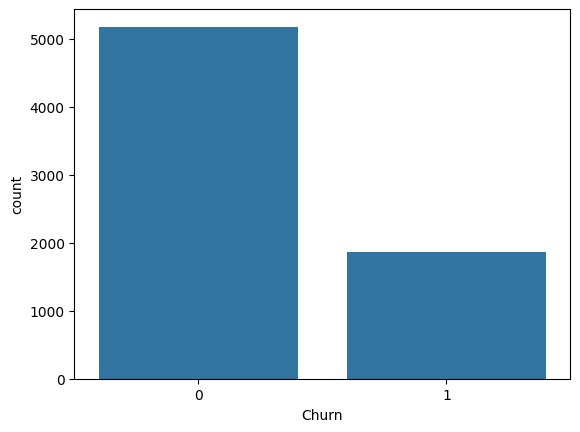

In [13]:
print(df["Churn"].value_counts(normalize=True))
sns.countplot(x="Churn", data=df)
plt.show()

Churn berdasarkan tipe kontrak

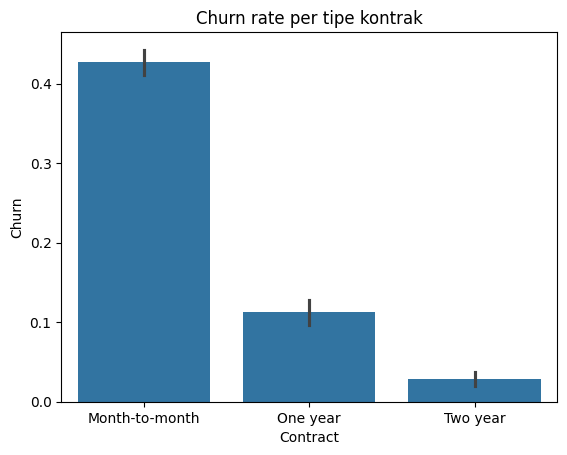

In [14]:
sns.barplot(x="Contract", y="Churn", data=df)
plt.title("Churn rate per tipe kontrak")
plt.show()

churn berdasarkan lama berlangganan

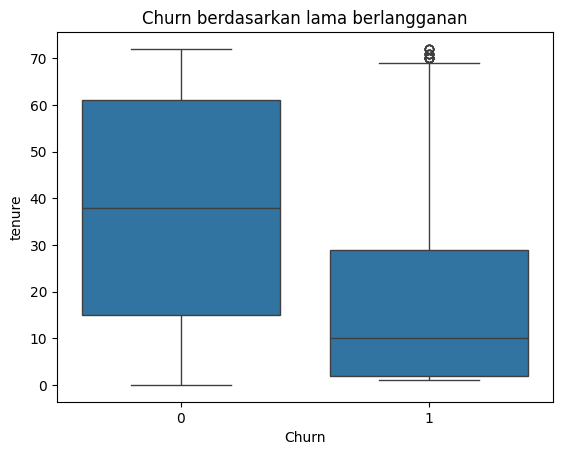

In [20]:
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Churn berdasarkan lama berlangganan")
plt.show()

Churn berdasarkan biaya

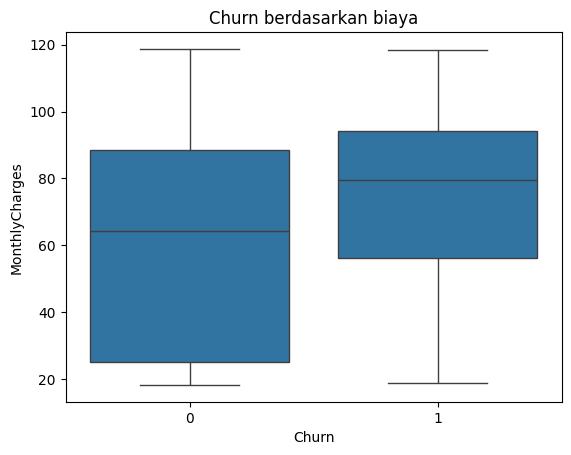

In [21]:
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Churn berdasarkan biaya")
plt.show()

Kategori lain

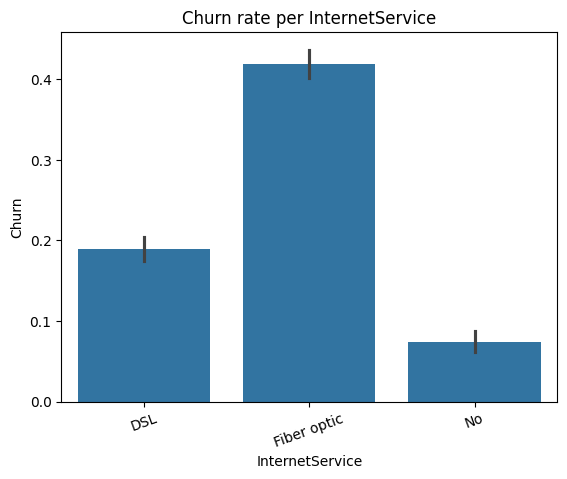

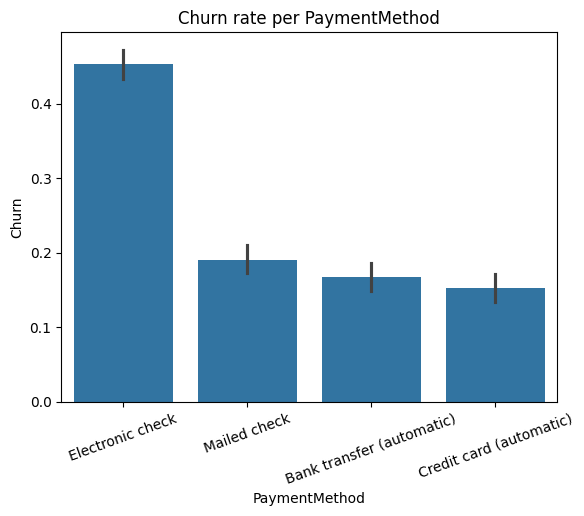

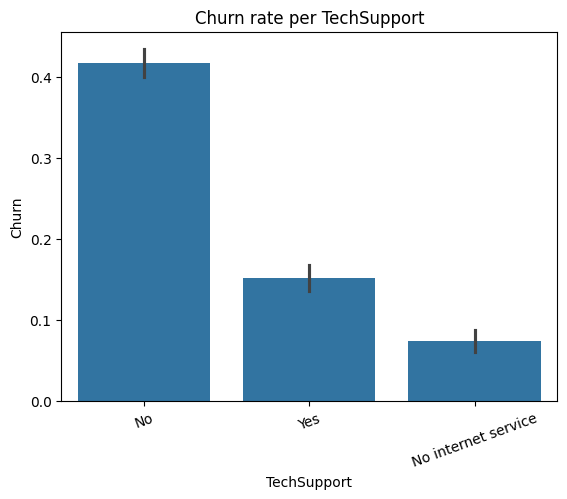

In [22]:
for col in ["InternetService", "PaymentMethod", "TechSupport"]:
    sns.barplot(x=col, y="Churn", data=df)
    plt.xticks(rotation=20)
    plt.title(f"Churn rate per {col}")
    plt.show()

Note :


1.   Terdapat **26% churn rate**
2.   Berdasarkan **tipe kontrak**, pelanggan dengan kontrak *month-to-month* **punya churn rate jauh lebih tinggi** dibandingkan kontrak 1 tahun atau 2 tahun.
3. Pelanggan dengan *tenure* rendah cenderung **lebih mudah churn**
4. *Monthly charges* yang lebih tinggi cenderung mempengaruhi churn rate
5. Pelanggan yang menggunakan *Fiber optic* sebagai internet service **lebih cenderung churn** daripada DSL
6. Pelanggan yang memakai *Electronic Check* sebagai cara pembayaran **lebih cenderung churn** dibandingkan denngan metode lain.
7. Pelanggan yang tidak mendapatkan *tech support* **lebih cenderung churn**.



5. Modelling

In [23]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X = pd.get_dummies(X, drop_first=True, dtype=int)
print(X.shape)
X.head()

(7043, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(y_train.mean(), y_test.mean())

0.2653532126375577 0.2654364797728886


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

preprocess = ColumnTransformer(
    [("num", StandardScaler(), num_cols)],
    remainder="passthrough"
)

log_reg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000))
])

log_reg.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('prep',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges'])])),
                ('model', LogisticRegression(max_iter=1000))])

6. Evaluasi

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

ROC-AUC: 0.8421710713270816


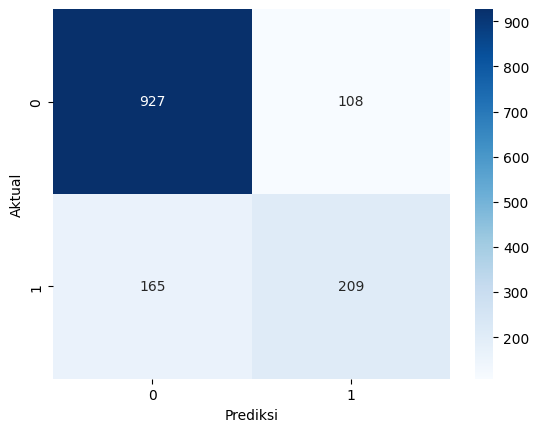

In [26]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

In [27]:
log_reg_bal = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
log_reg_bal.fit(X_train, y_train)
print(classification_report(y_test, log_reg_bal.predict(X_test)))

              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



Note:

7. Model lain (berbasis pohon)

In [28]:
pip install xgboost

In [34]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier as xgb

rf = RandomForestClassifier(
    n_estimators=300, max_depth=8, min_samples_leaf=5,
    random_state=42, n_jobs=-1
)

rf.fit(X_train, y_train)
gb = xgb(random_state=42)
gb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

Perbandingan hasil setiap model

In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {
    "Logistic Regression": log_reg,
    "Logistic Reg (balanced)": log_reg_bal,
    "Random Forest": rf,
    "Gradient Boosting": gb,
}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Precision (churn)": precision_score(y_test, pred),
        "Recall (churn)": recall_score(y_test, pred),
        "F1 (churn)": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

results = pd.DataFrame(rows).round(3).set_index("Model")
results

,Precision (churn),Recall (churn),F1 (churn),ROC-AUC
Model,,,,
Logistic Regression,0.659,0.559,0.605,0.842
Logistic Reg (balanced),0.504,0.783,0.614,0.842
Random Forest,0.675,0.489,0.567,0.845
Gradient Boosting,0.589,0.521,0.553,0.818


note:


1.   ROC-AUC semua model tidak memiliki perbedaan yang sangat signifikan
2. Model Random Forest memiliki ROC-AUC tertinggi namun memiliki recall paling rendah
3. Model Logistic Reg punya recall dan F1 tertinggi
4. Model Gradient Boosting adalah yang paling lemah




threshold untuk menaikkan recall

In [36]:
proba = log_reg.predict_proba(X_test)[:, 1]

for t in [0.5, 0.4, 0.3, 0.25]:
    pred = (proba >= t).astype(int)
    print(f"threshold={t}  precision={precision_score(y_test, pred):.2f}  "
          f"recall={recall_score(y_test, pred):.2f}  f1={f1_score(y_test, pred):.2f}")

threshold=0.5  precision=0.66  recall=0.56  f1=0.60
threshold=0.4  precision=0.57  recall=0.67  f1=0.61
threshold=0.3  precision=0.52  recall=0.76  f1=0.62
threshold=0.25  precision=0.50  recall=0.81  f1=0.62


feature importance

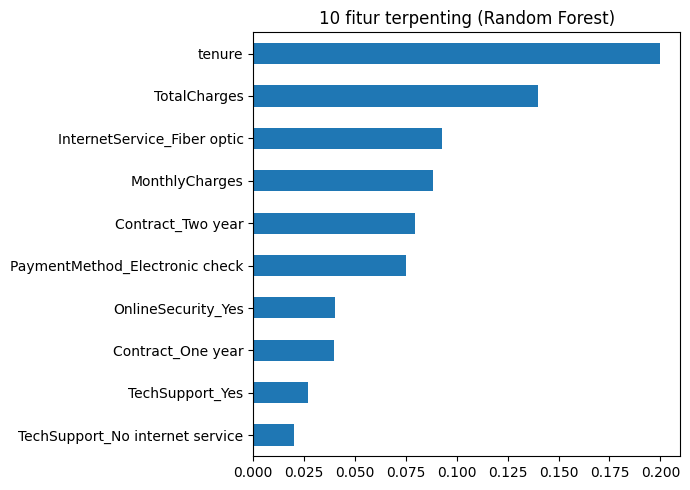

In [37]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
importances.sort_values().tail(10).plot(kind="barh", figsize=(7, 5))
plt.title("10 fitur terpenting (Random Forest)")
plt.tight_layout()
plt.show()

simpan model

In [38]:
import joblib

raw = df.drop(columns=["Churn"])
cat_cols = raw.select_dtypes(include="object").columns.tolist()
options = {c: sorted(raw[c].unique().tolist()) for c in cat_cols}

joblib.dump({
    "model": log_reg_bal,
    "columns": list(X_train.columns),
    "options": options,
    "threshold": 0.5,
}, "churn_artifacts.joblib")

['churn_artifacts.joblib']